# Native-rate ASG OUT1 to IN1 loopback test

This notebook tests the standard direct ASG-to-DAC path. Connect **OUT1 directly to IN1**. The ASG buffer contains zero padding followed by a `-1,+1` normalized alternating pattern. A full 16384-point buffer is replayed at one point per 125 MHz DAC clock, while IN1 is acquired at decimation 1.

The default amplitude is 0.8 V so overshoot can be measured without immediately clipping the nominal +/-1 V ADC range. Set `ASG_AMPLITUDE_V = 1.0` only after the 0.8 V run is clean.

**Bitstream prerequisite:** the current custom BNET top-level routes the physical DAC from `bnet_dac_dat`, not directly from `asg_dat`. On that image, `SOUR1:*` can configure the ASG but its waveform will not reach OUT1. Use the normal Red Pitaya ASG-routed bitstream for this isolation test, or add an explicit ASG bypass mux to the custom top-level. The analysis below detects a missing output route and reports it without stopping the notebook.


In [210]:
import time
import numpy as np
import matplotlib.pyplot as plt
import redpitaya_scpi as scpi

RP_IP = "169.254.77.151"
RP_PORT = 5000
SOCKET_TIMEOUT_S = 20.0

DAC_SAMPLE_RATE_HZ = 125_000_000.0
ASG_BUFFER_SAMPLES = 16_384
ASG_REPETITION_HZ = DAC_SAMPLE_RATE_HZ / ASG_BUFFER_SAMPLES
ASG_AMPLITUDE_V = 1
ASG_OFFSET_V = 0
PADDING_SAMPLES = 500
ALTERNATING_SAMPLES = 4_096
SYMBOL_HOLD_SAMPLES = 4  # 1 => 62.5 MHz; 2 => 31.25 MHz; each polarity gets the same hold time
ACQUISITION_SAMPLES = 16_384
ACQ_TRIGGER_SOURCE = "CH1_PE"  # "NOW", "CH1_PE", or "CH1_NE"
ACQ_TRIGGER_LEVEL = 0.05        # volts; ignored when source is NOW
ACQ_TRIGGER_DELAY_SAMPLES = 8100  # signed samples relative to the trigger
GENERATOR_SETTLE_S = 0.10
TRIGGER_TIMEOUT_S = 3.0
ACQ_FILL_TIMEOUT_S = 3.0

assert PADDING_SAMPLES + ALTERNATING_SAMPLES <= ASG_BUFFER_SAMPLES
assert SYMBOL_HOLD_SAMPLES >= 1
assert ALTERNATING_SAMPLES % (2 * SYMBOL_HOLD_SAMPLES) == 0
assert 0 < ASG_AMPLITUDE_V <= 1.0
if ASG_AMPLITUDE_V > 0.8:
    print("Warning: nominal levels leave little ADC headroom for measuring overshoot")
print(f"ASG repetition frequency: {ASG_REPETITION_HZ:.9f} Hz")
print(f"Active alternating frequency: {DAC_SAMPLE_RATE_HZ / (2 * SYMBOL_HOLD_SAMPLES) / 1e6:.3f} MHz")
print(f"Acquisition trigger: source={ACQ_TRIGGER_SOURCE}, level={ACQ_TRIGGER_LEVEL} V, delay={ACQ_TRIGGER_DELAY_SAMPLES} samples")


ASG repetition frequency: 7629.394531250 Hz
Active alternating frequency: 15.625 MHz
Acquisition trigger: source=CH1_PE, level=0.05 V, delay=8100 samples


In [211]:
rp = scpi.scpi(RP_IP, timeout=SOCKET_TIMEOUT_S, port=RP_PORT)

def command(message: str, *, check: bool = True) -> None:
    print(f">> {message if len(message) < 160 else message[:157] + '...'}")
    rp.tx_txt(message)
    if check:
        error = rp.txrx_txt("SYST:ERR:NEXT?")
        if not error.startswith("0,"):
            raise RuntimeError(f"{message[:80]} failed: {error}")

def query(message: str, *, check: bool = True) -> str:
    print(f">> {message}")
    response = rp.txrx_txt(message)
    print(f"<< {response}")
    if check:
        error = rp.txrx_txt("SYST:ERR:NEXT?")
        if not error.startswith("0,"):
            raise RuntimeError(f"{message} failed: {error}")
    return response

def parse_ascii_array(text: str) -> np.ndarray:
    cleaned = text.strip().strip("{}")
    if not cleaned:
        return np.empty(0, dtype=np.float64)
    return np.fromstring(cleaned, sep=",", dtype=np.float64)

def wait_for_trigger(timeout_s: float = TRIGGER_TIMEOUT_S) -> str:
    deadline = time.time() + timeout_s
    state = ""
    while time.time() < deadline:
        state = query("ACQ:TRig:STAT?", check=False)
        if state.upper().startswith("TD"):
            return state
        time.sleep(0.05)
    return state

def wait_for_acquisition_fill(timeout_s: float = ACQ_FILL_TIMEOUT_S) -> bool:
    deadline = time.time() + timeout_s
    while time.time() < deadline:
        try:
            if int(float(query("ACQ:TRig:FILL?", check=False))) != 0:
                return True
        except (TypeError, ValueError):
            pass
        time.sleep(0.05)
    return False

command("*CLS", check=False)
print(query("*IDN?", check=False))


>> *CLS
>> *IDN?
<< REDPITAYA,INSTR2025,,01-21
REDPITAYA,INSTR2025,,01-21


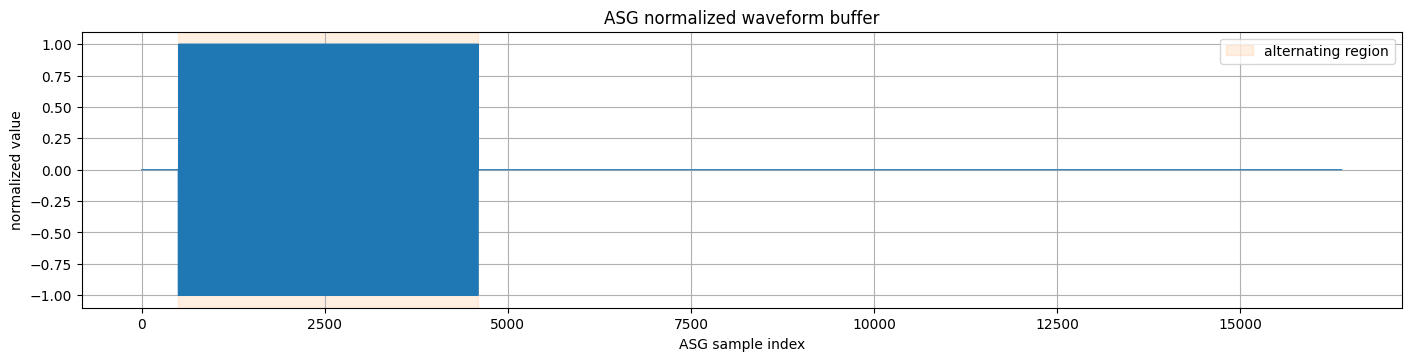

In [212]:
normalized_waveform = np.zeros(ASG_BUFFER_SAMPLES, dtype=np.float64)
active_start = PADDING_SAMPLES
active_stop = active_start + ALTERNATING_SAMPLES
# Hold -1 and +1 for the same number of DAC clocks. Using `index % 3 == 0`
# would instead produce one -1 clock followed by two +1 clocks and a DC bias.
symbol_index = np.arange(ALTERNATING_SAMPLES) // SYMBOL_HOLD_SAMPLES
normalized_waveform[active_start:active_stop] = np.where(
    symbol_index % 2 == 0, -1.0, 1.0
)
expected_voltage = normalized_waveform * ASG_AMPLITUDE_V + ASG_OFFSET_V

fig, ax = plt.subplots(figsize=(14, 3.5), constrained_layout=True)
ax.plot(normalized_waveform, linewidth=0.8)
ax.axvspan(active_start, active_stop, color="C1", alpha=0.12, label="alternating region")
ax.set_title("ASG normalized waveform buffer")
ax.set_xlabel("ASG sample index")
ax.set_ylabel("normalized value")
ax.grid(True)
ax.legend()
plt.show()


In [213]:
def upload_asg_waveform(values: np.ndarray) -> None:
    payload = ",".join(f"{value:.7g}" for value in values)
    command(f"SOUR1:TRAC:DATA:DATA {payload}")

def acquire_latest_input1(samples: int) -> np.ndarray:
    command("ACQ:RST")
    command("ACQ:DATA:Units VOLTS")
    command("ACQ:DATA:FORMAT ASCII")
    command("ACQ:DEC 1")
    command("ACQ:AVG OFF")
    command(f"ACQ:TRig:DLY {ACQ_TRIGGER_DELAY_SAMPLES}")
    command(f"ACQ:TRig:LEV {ACQ_TRIGGER_LEVEL}")
    command("ACQ:START")
    time.sleep(0.05)
    trigger_source = str(ACQ_TRIGGER_SOURCE).strip().upper()
    if trigger_source == "NOW":
        command("SOUR1:TRig:INT")
        time.sleep(GENERATOR_SETTLE_S)
        command("ACQ:TRig NOW")
    else:
        # Arm the level detector before starting the ASG, matching the working BNET loopback sequence.
        command(f"ACQ:TRig {trigger_source}")
        command("SOUR1:TRig:INT")
    trigger_state = wait_for_trigger()
    if not trigger_state.upper().startswith("TD") and trigger_source != "NOW":
        print(f"WARNING: {trigger_source} did not cross {ACQ_TRIGGER_LEVEL} V; forcing NOW to inspect IN1 anyway.")
        command("ACQ:TRig NOW")
        trigger_state = wait_for_trigger()
    if not trigger_state.upper().startswith("TD"):
        raise TimeoutError(f"Acquisition did not trigger even with diagnostic fallback: {trigger_state!r}")
    fill_ok = wait_for_acquisition_fill()
    print(f"Acquisition trigger state={trigger_state}, buffer_fill={fill_ok}")
    if not fill_ok:
        print("WARNING: acquisition buffer did not report full; reading latest samples anyway.")
    rp.tx_txt(f"ACQ:SOUR1:DATA:LATest:N? {samples}")
    captured = parse_ascii_array(rp.rx_txt())
    command("ACQ:STOP")
    if captured.size != samples:
        raise RuntimeError(f"Expected {samples} acquisition samples, received {captured.size}")
    return captured

captured_voltage = None
try:
    command("GEN:RST")
    command("SOUR1:FUNC ARBITRARY")
    upload_asg_waveform(normalized_waveform)
    command(f"SOUR1:FREQ:FIX {ASG_REPETITION_HZ:.12f}")
    command(f"SOUR1:VOLT {ASG_AMPLITUDE_V}")
    command(f"SOUR1:VOLT:OFFS {ASG_OFFSET_V}")
    print("Generator frequency readback:", query("SOUR1:FREQ:FIX?"))
    print("Generator amplitude readback:", query("SOUR1:VOLT?"))
    command("OUTPUT1:STATE ON")
    print("RF output 1 state:", query("OUTPUT1:STATE?"))
    captured_voltage = acquire_latest_input1(ACQUISITION_SAMPLES)
finally:
    try:
        command("ACQ:STOP", check=False)
        command("OUTPUT1:STATE OFF", check=False)
    except Exception as cleanup_error:
        print("Cleanup warning:", cleanup_error)

print(f"Captured {captured_voltage.size} samples at 125 MHz")


>> GEN:RST
>> SOUR1:FUNC ARBITRARY
>> SOUR1:TRAC:DATA:DATA 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...
>> SOUR1:FREQ:FIX 7629.394531250000
>> SOUR1:VOLT 1
>> SOUR1:VOLT:OFFS 0
>> SOUR1:FREQ:FIX?
<< 7629.39
Generator frequency readback: 7629.39
>> SOUR1:VOLT?
<< 1
Generator amplitude readback: 1
>> OUTPUT1:STATE ON
>> OUTPUT1:STATE?
<< ON
RF output 1 state: ON
>> ACQ:RST
>> ACQ:DATA:Units VOLTS
>> ACQ:DATA:FORMAT ASCII
>> ACQ:DEC 1
>> ACQ:AVG OFF
>> ACQ:TRig:DLY 8100
>> ACQ:TRig:LEV 0.05
>> ACQ:START
>> ACQ:TRig CH1_PE
>> SOUR1:TRig:INT
>> ACQ:TRig:STAT?
<< TD
>> ACQ:TRig:FILL?
<< 1
Acquisition trigger state=TD, buffer_fill=True
>> ACQ:STOP
>> ACQ:STOP
>> OUTPUT1:STATE OFF
Captured 16384 samples at 125 MHz


In [214]:
def circular_align(captured: np.ndarray, expected: np.ndarray) -> tuple[np.ndarray, int]:
    y = np.asarray(captured, dtype=np.float64) - np.mean(captured)
    x = np.asarray(expected, dtype=np.float64) - np.mean(expected)
    correlation = np.fft.ifft(np.fft.fft(y) * np.conj(np.fft.fft(x))).real
    shift = int(np.argmax(np.abs(correlation)))
    return np.roll(captured, -shift), shift

captured_aligned, circular_shift = circular_align(captured_voltage, expected_voltage)
design = np.column_stack((expected_voltage, np.ones(expected_voltage.size)))
gain, offset = np.linalg.lstsq(design, captured_aligned, rcond=None)[0]
fitted = gain * expected_voltage + offset
residual = captured_aligned - fitted
correlation = float(np.corrcoef(captured_aligned, expected_voltage)[0, 1])
normalized_rmse = float(np.sqrt(np.mean(residual ** 2)) / max(np.std(captured_aligned), 1e-15))

positive = normalized_waveform > 0
negative = normalized_waveform < 0
padding = normalized_waveform == 0
positive_mean = float(np.mean(captured_aligned[positive]))
negative_mean = float(np.mean(captured_aligned[negative]))
positive_std = float(np.std(captured_aligned[positive]))
negative_std = float(np.std(captured_aligned[negative]))
padding_mean = float(np.mean(captured_aligned[padding]))
padding_rms = float(np.sqrt(np.mean((captured_aligned[padding] - padding_mean) ** 2)))
measured_amplitude = 0.5 * (positive_mean - negative_mean)
amplitude_ratio = measured_amplitude / ASG_AMPLITUDE_V
high_overshoot = float(np.max(captured_aligned[positive]) - positive_mean)
low_overshoot = float(negative_mean - np.min(captured_aligned[negative]))
peak_error = float(np.max(np.abs(residual)))
captured_peak_to_peak = float(np.ptp(captured_voltage))
direct_asg_signal_detected = captured_peak_to_peak >= 0.25 * ASG_AMPLITUDE_V

asg_metrics = {
    "circular_shift": circular_shift,
    "correlation": correlation,
    "fit_gain": float(gain),
    "fit_offset_v": float(offset),
    "normalized_rmse": normalized_rmse,
    "positive_mean_v": positive_mean,
    "negative_mean_v": negative_mean,
    "positive_std_v": positive_std,
    "negative_std_v": negative_std,
    "measured_amplitude_v": measured_amplitude,
    "amplitude_ratio": amplitude_ratio,
    "padding_mean_v": padding_mean,
    "padding_rms_v": padding_rms,
    "positive_overshoot_v": high_overshoot,
    "negative_overshoot_v": low_overshoot,
    "peak_fit_error_v": peak_error,
    "captured_peak_to_peak_v": captured_peak_to_peak,
    "direct_asg_signal_detected": direct_asg_signal_detected,
}
for name, value in asg_metrics.items():
    print(f"{name:24s}: {value}")

if not direct_asg_signal_detected:
    print("RESULT: No substantial ASG waveform reached IN1. Check OUT1-to-IN1 cabling and use a bitstream with a direct ASG-to-DAC route.")
elif correlation > 0.95 and normalized_rmse < 0.25:
    print("RESULT: The native-rate ASG loopback follows the alternating pattern well.")
elif abs(correlation) > 0.80:
    print("RESULT: The pattern is recognizable but materially attenuated or distorted.")
else:
    print("RESULT: The 62.5 MHz alternating pattern is not reproduced reliably end to end.")
asg_metrics


circular_shift          : 15972
correlation             : 0.9408287112731248
fit_gain                : 0.6355573391113275
fit_offset_v            : -0.00023075280761718914
normalized_rmse         : 0.3388824811703198
positive_mean_v         : 0.6274578359374999
negative_mean_v         : -0.6436568422851563
positive_std_v          : 0.23803414167101752
negative_std_v          : 0.21839183067047313
measured_amplitude_v    : 0.6355573391113281
amplitude_ratio         : 0.6355573391113281
padding_mean_v          : 0.0023921639811197914
padding_rms_v           : 0.006987949859995796
positive_overshoot_v    : 0.37229816406250005
negative_overshoot_v    : 0.3563431577148437
peak_fit_error_v        : 0.5360242471923828
captured_peak_to_peak_v : 1.999756
direct_asg_signal_detected: True
RESULT: The pattern is recognizable but materially attenuated or distorted.


{'circular_shift': 15972,
 'correlation': 0.9408287112731248,
 'fit_gain': 0.6355573391113275,
 'fit_offset_v': -0.00023075280761718914,
 'normalized_rmse': 0.3388824811703198,
 'positive_mean_v': 0.6274578359374999,
 'negative_mean_v': -0.6436568422851563,
 'positive_std_v': 0.23803414167101752,
 'negative_std_v': 0.21839183067047313,
 'measured_amplitude_v': 0.6355573391113281,
 'amplitude_ratio': 0.6355573391113281,
 'padding_mean_v': 0.0023921639811197914,
 'padding_rms_v': 0.006987949859995796,
 'positive_overshoot_v': 0.37229816406250005,
 'negative_overshoot_v': 0.3563431577148437,
 'peak_fit_error_v': 0.5360242471923828,
 'captured_peak_to_peak_v': 1.999756,
 'direct_asg_signal_detected': True}

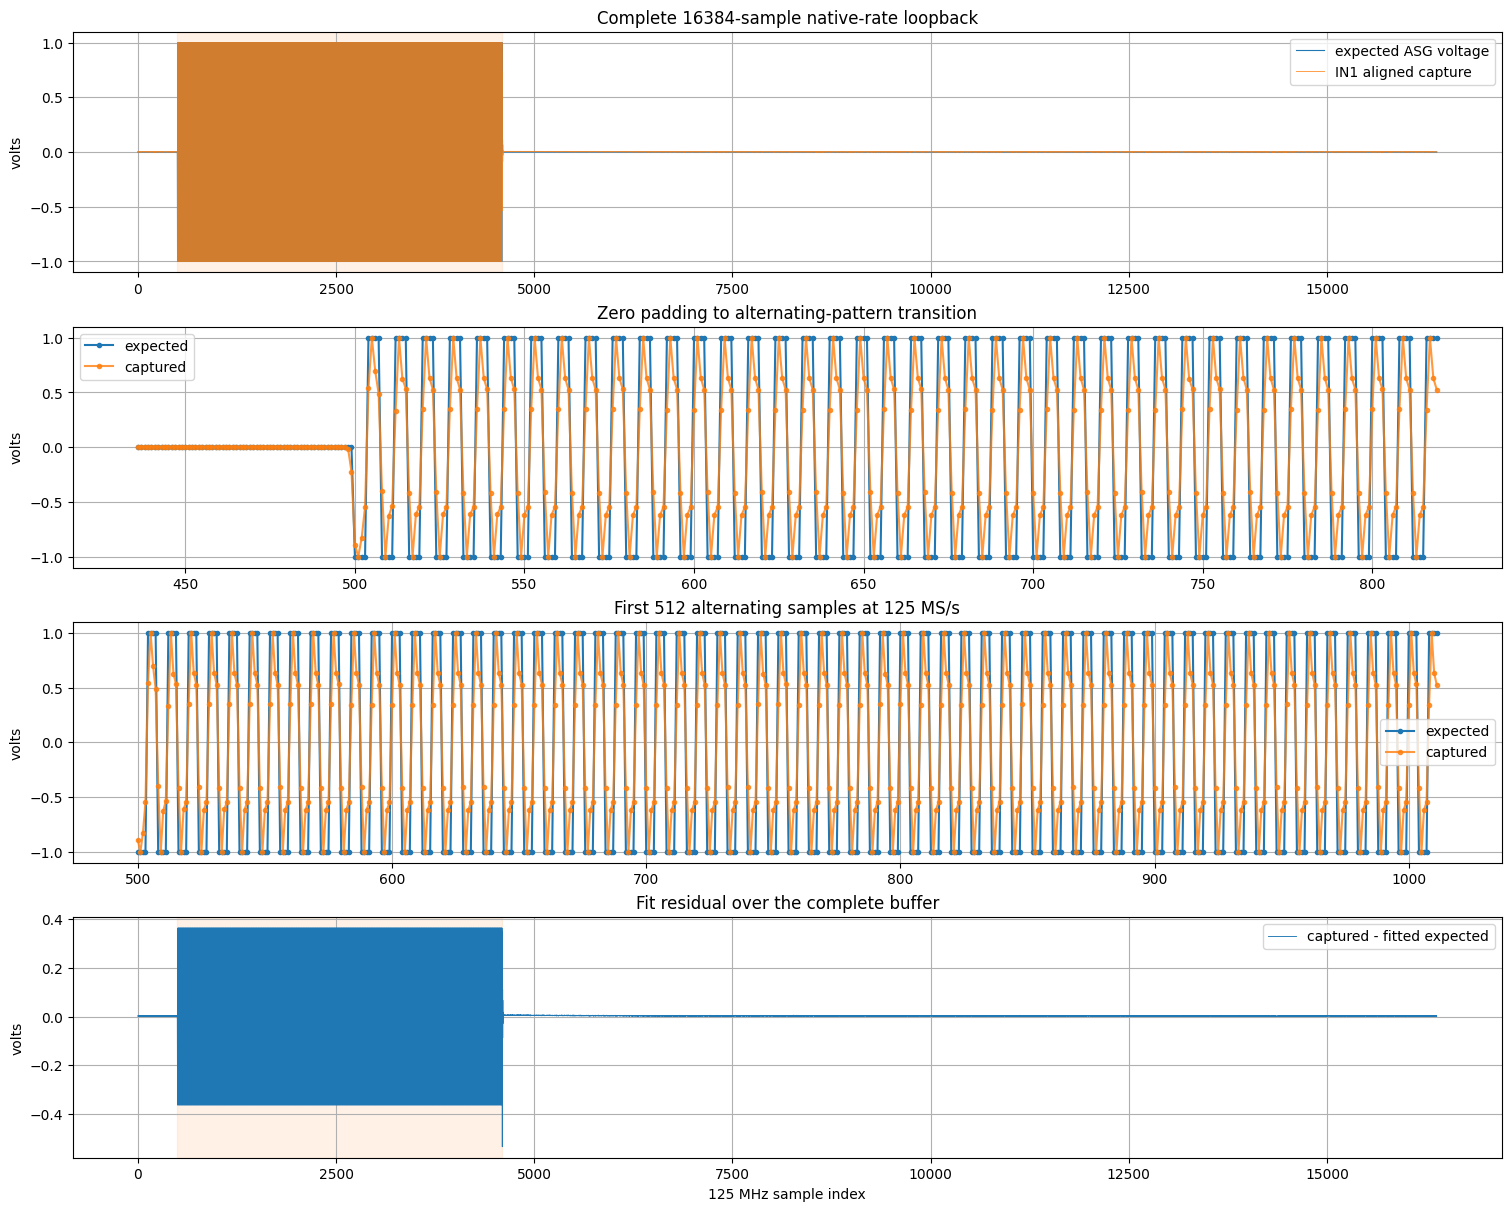

In [215]:
zoom_before = 64
zoom_after = 320
zoom_start = active_start - zoom_before
zoom_stop = active_start + zoom_after
active_zoom_stop = active_start + 512

fig, axes = plt.subplots(4, 1, figsize=(15, 12), constrained_layout=True)
axes[0].plot(expected_voltage, label="expected ASG voltage", linewidth=0.8)
axes[0].plot(captured_aligned, label="IN1 aligned capture", linewidth=0.65, alpha=0.8)
axes[0].axvspan(active_start, active_stop, color="C1", alpha=0.10)
axes[0].set_title("Complete 16384-sample native-rate loopback")
axes[0].set_ylabel("volts")
axes[0].grid(True)
axes[0].legend()

x_zoom = np.arange(zoom_start, zoom_stop)
axes[1].plot(x_zoom, expected_voltage[zoom_start:zoom_stop], marker=".", label="expected")
axes[1].plot(x_zoom, captured_aligned[zoom_start:zoom_stop], marker=".", label="captured", alpha=0.8)
axes[1].set_title("Zero padding to alternating-pattern transition")
axes[1].set_ylabel("volts")
axes[1].grid(True)
axes[1].legend()

x_active = np.arange(active_start, active_zoom_stop)
axes[2].plot(x_active, expected_voltage[active_start:active_zoom_stop], marker=".", label="expected")
axes[2].plot(x_active, captured_aligned[active_start:active_zoom_stop], marker=".", label="captured", alpha=0.8)
axes[2].set_title("First 512 alternating samples at 125 MS/s")
axes[2].set_ylabel("volts")
axes[2].grid(True)
axes[2].legend()

axes[3].plot(residual, linewidth=0.65, label="captured - fitted expected")
axes[3].axvspan(active_start, active_stop, color="C1", alpha=0.10)
axes[3].set_title("Fit residual over the complete buffer")
axes[3].set_xlabel("125 MHz sample index")
axes[3].set_ylabel("volts")
axes[3].grid(True)
axes[3].legend()
plt.show()


## Interpretation

A clean result requires the positive and negative sample clouds to be narrow, similar in width, correctly alternating, and free of clipping. Strong attenuation does not by itself prove a DAC logic bug: the `-1,+1` sequence is a 62.5 MHz Nyquist pattern, so DAC reconstruction bandwidth, analog output bandwidth, cable/load impedance, ADC bandwidth, and relative sampling phase affect it.

Compare the positive and negative standard deviations. If only one polarity is unstable here, the asymmetry is in the standard analog path. If both polarities are clean here but BNET high fields remain unstable, the fault is in BNET serialization, framing, or its timing relative to the DAC.

A 125 MS/s update rate does not guarantee that a full-scale transition settles in 8 ns. The alternating sequence is a 62.5 MHz waveform at Nyquist; the DAC reconstruction response, output amplifier bandwidth, cable/load, ADC input bandwidth, and DAC-to-ADC sampling phase all affect its measured amplitude and shape. This test is still useful because polarity-dependent errors in the ordinary ASG path can be compared directly with the BNET split-symbol behavior.
